<a href="https://colab.research.google.com/github/abhiram54369/california-housing-ml-analysis/blob/main/ml__mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data: (20640, 9)  |  Train: 16512  Test: 4128

REGRESSION MODELS (test set)
                              Model    MAE    MSE   RMSE     R2
         Multiple Linear Regression 0.5332 0.5559 0.7456 0.5758
                      Decision Tree 0.4482 0.4220 0.6497 0.6779
Multiple Linear Regression + KMeans 0.5319 0.5595 0.7480 0.5730
             Decision Tree + KMeans 0.4482 0.4223 0.6499 0.6777

K-MEANS CLUSTERING
 Clusters    Inertia  Silhouette (train)  Silhouette (test)
        3 87058.9773              0.3333             0.3367

CLUSTER PROFILE (train)
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  Size  AvgPrice
Cluster                                                                                                  
0          3.82     28.89      5.51       1.08     1299.21      3.17     37.95    -121.74  6937     1.980
1          3.93     28.47      5.21       1.07     1526.85      3.04     33.95    -118.01  9510     2.142
2          3.34

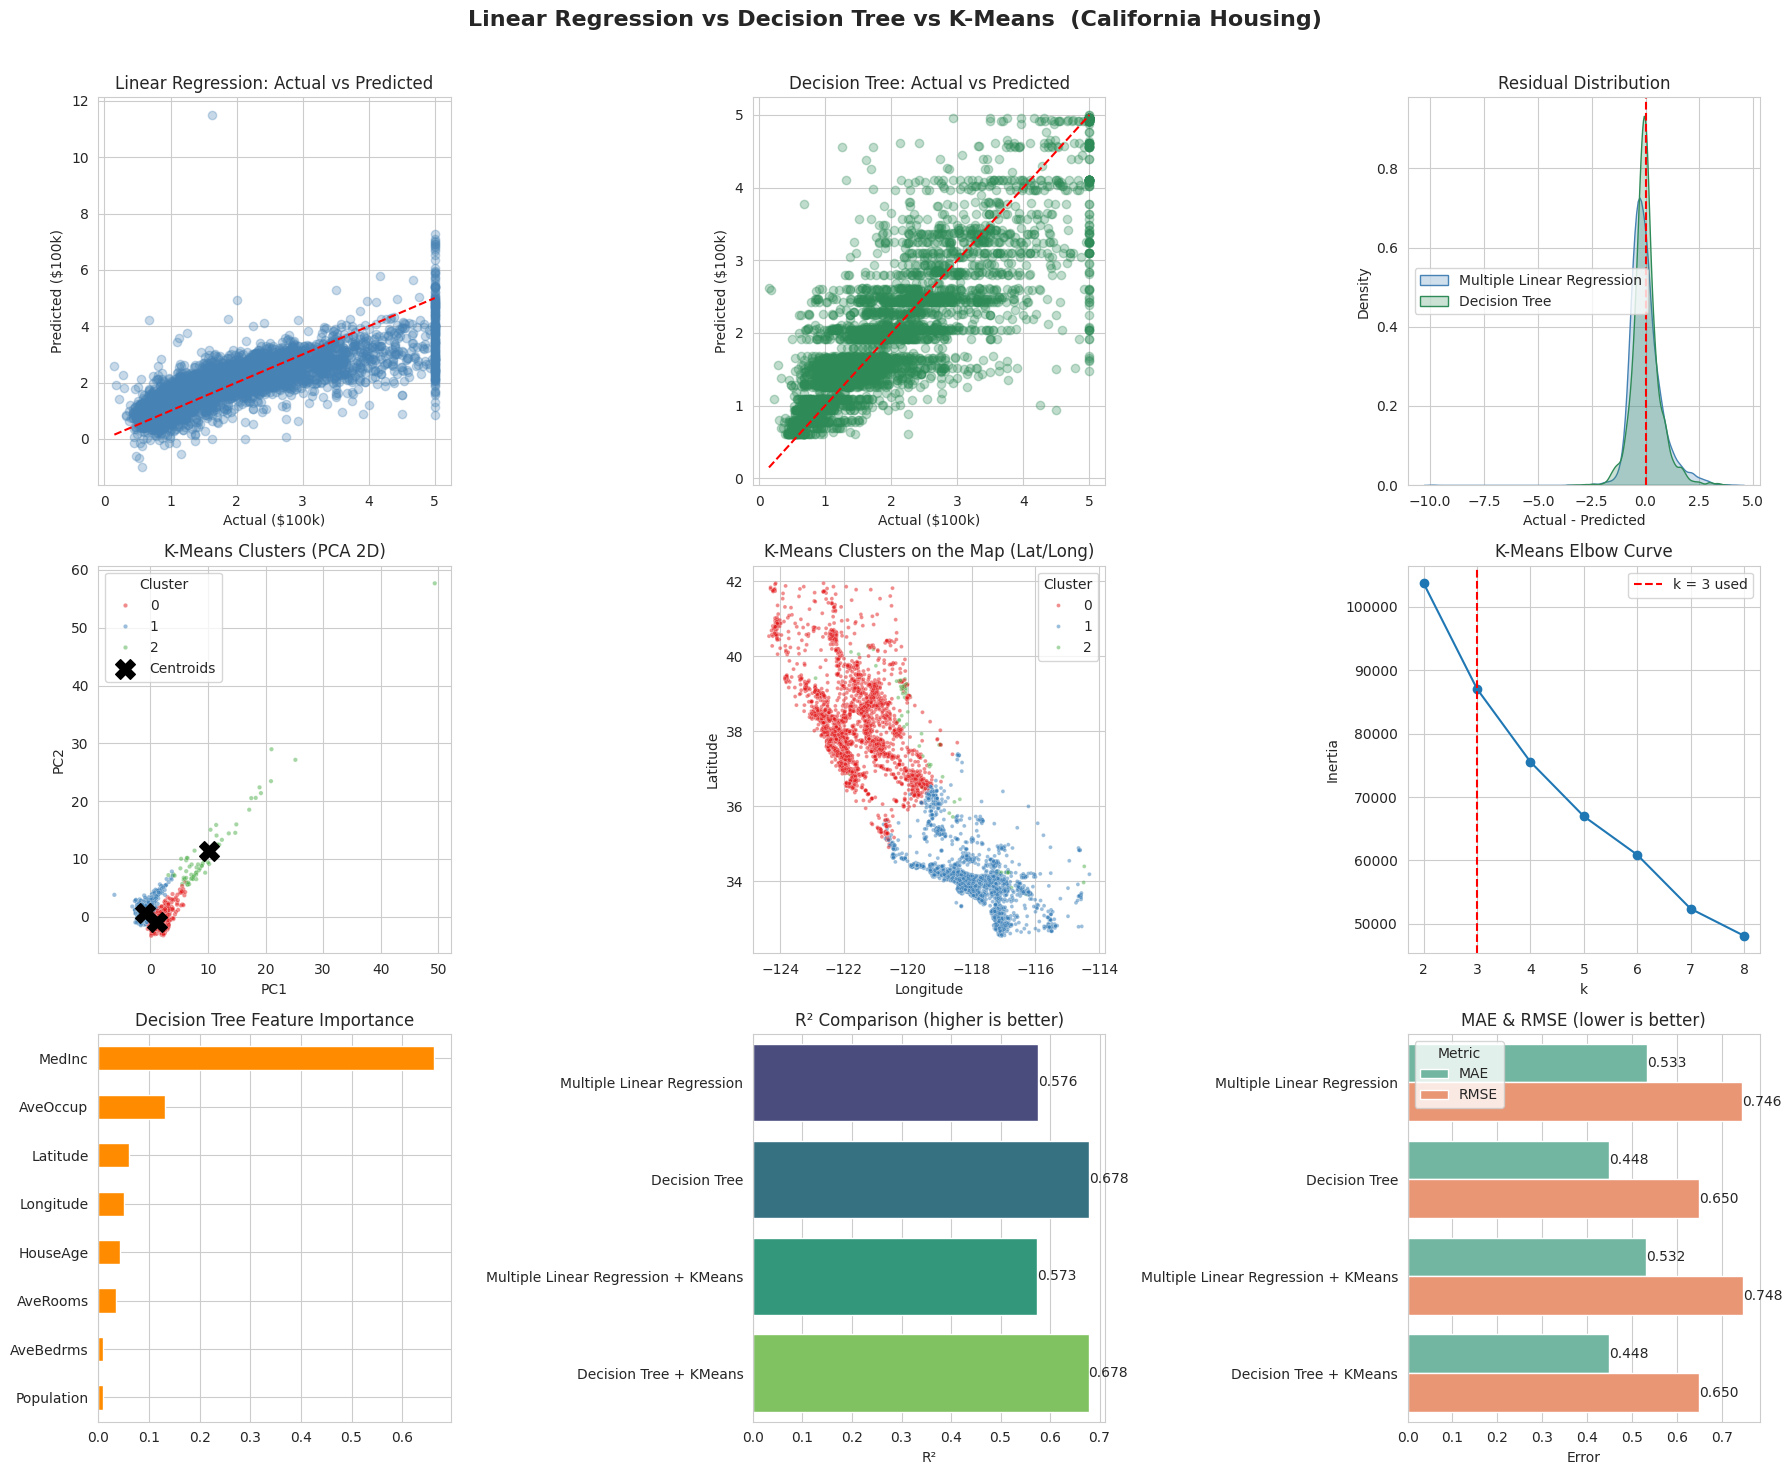

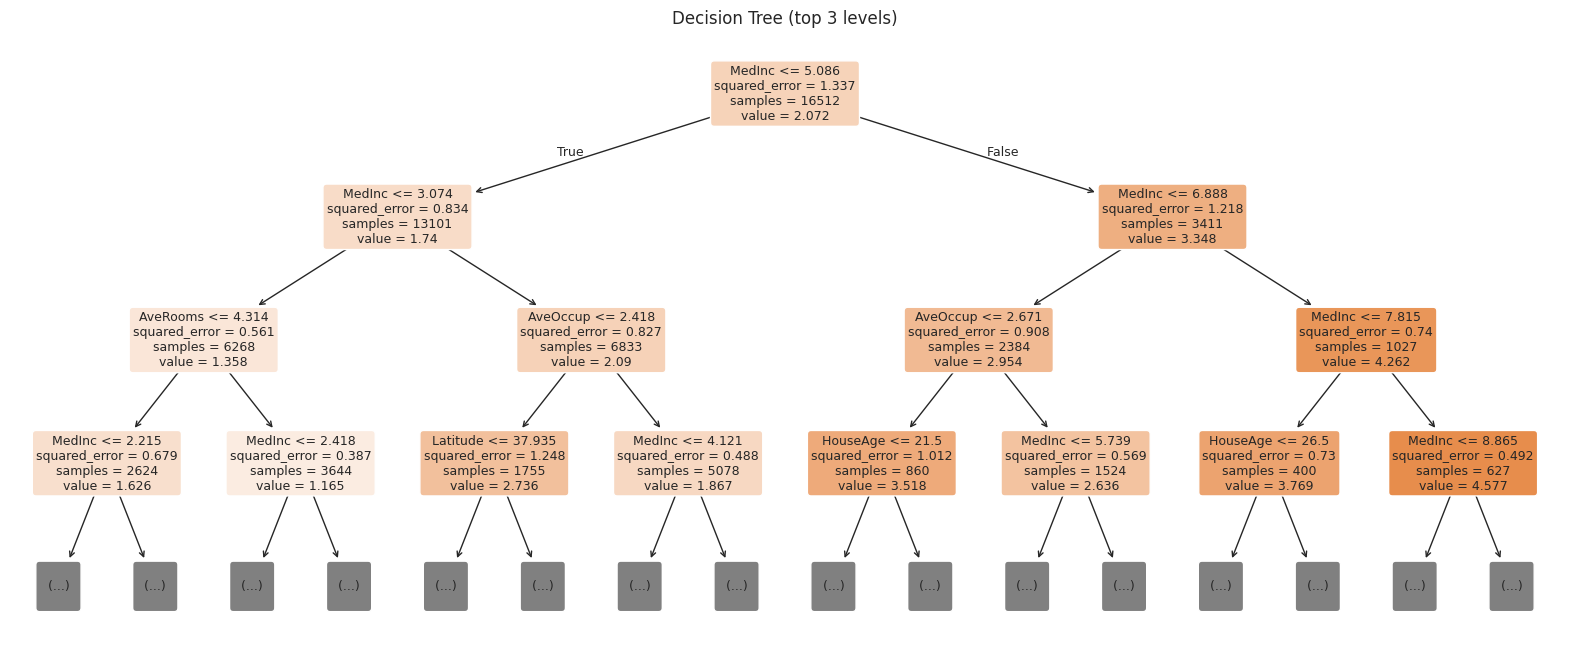

In [1]:
"""
Combined ML pipeline: Multiple Linear Regression + Decision Tree + K-Means
Dataset: California Housing (scikit-learn)
All three models are trained, evaluated and plotted in a single run.
Works in Colab / Jupyter / VS Code (python combined_3_models.py).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, silhouette_score)

RS = 42
sns.set_style("whitegrid")

# ------------------------------------------------------------------
# 1. DATA
# ------------------------------------------------------------------
df = fetch_california_housing(as_frame=True).frame
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS)
print(f"Data: {df.shape}  |  Train: {len(X_train)}  Test: {len(X_test)}")

# ------------------------------------------------------------------
# 2. MODEL 3 FIRST: K-MEANS (fit on TRAIN only -> no data leakage)
#    Its cluster label is then fed to the two regression models.
# ------------------------------------------------------------------
scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

kmeans = KMeans(n_clusters=3, random_state=RS, n_init=10).fit(Xtr_s)
tr_clu, te_clu = kmeans.labels_, kmeans.predict(Xte_s)

inertia = kmeans.inertia_
sil = silhouette_score(Xtr_s, tr_clu)
sil_test = silhouette_score(Xte_s, te_clu)

# add cluster label (one-hot) as an extra feature for the regressors
def add_cluster(Xdf, labels):
    Xc = Xdf.copy()
    for k in range(3):
        Xc[f"Cluster_{k}"] = (labels == k).astype(int)
    return Xc

Xtr_c, Xte_c = add_cluster(X_train, tr_clu), add_cluster(X_test, te_clu)

# ------------------------------------------------------------------
# 3. MODELS 1 & 2: LINEAR REGRESSION + DECISION TREE
#    Each is trained twice: plain features, and features + K-Means cluster
# ------------------------------------------------------------------
def make_models():
    return {"Multiple Linear Regression": LinearRegression(),
            "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=RS)}

preds, fitted = {}, {}
for name, m in make_models().items():                      # plain
    m.fit(X_train, y_train); preds[name] = m.predict(X_test); fitted[name] = m
for name, m in make_models().items():                      # + K-Means feature
    label = name + " + KMeans"
    m.fit(Xtr_c, y_train); preds[label] = m.predict(Xte_c); fitted[label] = m

# ------------------------------------------------------------------
# 4. EVALUATION (all three models together)
# ------------------------------------------------------------------
rows = []
for name, p in preds.items():
    mse = mean_squared_error(y_test, p)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "MSE": mse,
                 "RMSE": np.sqrt(mse),
                 "R2": r2_score(y_test, p)})
results = pd.DataFrame(rows)

km_results = pd.DataFrame({"Clusters": [3], "Inertia": [inertia],
                           "Silhouette (train)": [sil],
                           "Silhouette (test)": [sil_test]})

cluster_profile = X_train.assign(Cluster=tr_clu).groupby("Cluster").mean().round(2)
cluster_profile["Size"] = pd.Series(tr_clu).value_counts().sort_index()
cluster_profile["AvgPrice"] = y_train.groupby(tr_clu).mean().round(3)

print("\n" + "=" * 70)
print("REGRESSION MODELS (test set)")
print(results.round(4).to_string(index=False))
print("\nK-MEANS CLUSTERING")
print(km_results.round(4).to_string(index=False))
print("\nCLUSTER PROFILE (train)")
print(cluster_profile.to_string())

base = results.iloc[[0, 1]]
best = base.loc[base["R2"].idxmax()]
print("\n" + "=" * 70)
print(f"Best regression model (plain features): {best['Model']}  "
      f"R2={best['R2']:.4f}  MAE={best['MAE']:.4f}  RMSE={best['RMSE']:.4f}")
for n in ["Multiple Linear Regression", "Decision Tree"]:
    d = results.set_index("Model").loc[n + " + KMeans", "R2"] - results.set_index("Model").loc[n, "R2"]
    print(f"Effect of adding K-Means cluster feature on {n}: R2 change = {d:+.4f}")
print(f"K-Means silhouette = {sil:.4f} -> "
      + ("well separated" if sil >= 0.5 else "moderate structure, overlapping" if sil >= 0.25 else "weak, overlapping clusters"))

# ------------------------------------------------------------------
# 5. GRAPHS  (one dashboard + saved PNG)
# ------------------------------------------------------------------
lim = [y_test.min(), y_test.max()]
fig, ax = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle("Linear Regression vs Decision Tree vs K-Means  (California Housing)",
             fontsize=16, fontweight="bold")

# (1) LR actual vs predicted
a = ax[0, 0]; a.scatter(y_test, preds["Multiple Linear Regression"], alpha=.3, color="steelblue")
a.plot(lim, lim, "r--"); a.set(title="Linear Regression: Actual vs Predicted",
                               xlabel="Actual ($100k)", ylabel="Predicted ($100k)")
# (2) DT actual vs predicted
a = ax[0, 1]; a.scatter(y_test, preds["Decision Tree"], alpha=.3, color="seagreen")
a.plot(lim, lim, "r--"); a.set(title="Decision Tree: Actual vs Predicted",
                               xlabel="Actual ($100k)", ylabel="Predicted ($100k)")
# (3) Residual distributions
a = ax[0, 2]
for n, c in [("Multiple Linear Regression", "steelblue"), ("Decision Tree", "seagreen")]:
    sns.kdeplot(y_test - preds[n], ax=a, color=c, label=n, fill=True, alpha=.25)
a.axvline(0, color="r", ls="--"); a.set(title="Residual Distribution", xlabel="Actual - Predicted"); a.legend()

# (4) K-Means PCA clusters
pca = PCA(n_components=2, random_state=RS)
X2 = pca.fit_transform(Xtr_s); C2 = pca.transform(kmeans.cluster_centers_)
a = ax[1, 0]
sns.scatterplot(x=X2[:, 0], y=X2[:, 1], hue=tr_clu, palette="Set1", s=10, alpha=.5, ax=a)
a.scatter(C2[:, 0], C2[:, 1], c="black", marker="X", s=200, label="Centroids")
a.set(title="K-Means Clusters (PCA 2D)", xlabel="PC1", ylabel="PC2"); a.legend(title="Cluster")
# (5) K-Means geographic map
a = ax[1, 1]
sns.scatterplot(x=X_train["Longitude"], y=X_train["Latitude"], hue=tr_clu,
                palette="Set1", s=8, alpha=.5, ax=a)
a.set(title="K-Means Clusters on the Map (Lat/Long)"); a.legend(title="Cluster")
# (6) Elbow curve
a = ax[1, 2]
ks = range(2, 9)
inert = [KMeans(n_clusters=k, random_state=RS, n_init=10).fit(Xtr_s).inertia_ for k in ks]
a.plot(list(ks), inert, "o-"); a.axvline(3, color="r", ls="--", label="k = 3 used")
a.set(title="K-Means Elbow Curve", xlabel="k", ylabel="Inertia"); a.legend()

# (7) Feature importance (DT)
a = ax[2, 0]
imp = pd.Series(fitted["Decision Tree"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="darkorange", ax=a); a.set(title="Decision Tree Feature Importance")
# (8) R2 comparison
a = ax[2, 1]
sns.barplot(x="R2", y="Model", data=results, hue="Model", palette="viridis", legend=False, ax=a)
for c in a.containers: a.bar_label(c, fmt="%.3f")
a.set(title="R² Comparison (higher is better)", xlabel="R²", ylabel="")
# (9) MAE / RMSE comparison
a = ax[2, 2]
err = results.melt(id_vars="Model", value_vars=["MAE", "RMSE"], var_name="Metric", value_name="Error")
sns.barplot(y="Model", x="Error", hue="Metric", data=err, palette="Set2", ax=a)
for c in a.containers: a.bar_label(c, fmt="%.3f")
a.set(title="MAE & RMSE (lower is better)", ylabel="")
print("dataset sample")
print(df.head())
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("combined_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

# (extra) Decision tree structure (top 3 levels)
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 8))
plot_tree(fitted["Decision Tree"], max_depth=3, feature_names=X.columns, filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (top 3 levels)")
plt.savefig("decision_tree_structure.png", dpi=150, bbox_inches="tight")
plt.show()